# NumCompute-Stream: streaming decision tree demo

Steps in this notebook:

1. Load `demo/data/sensor_stream.csv` with `numcompute_stream.io`.
2. Read it in chunks of 100 rows to simulate a stream.
3. Train a pipeline (impute, scale and one-hot, then a buffered decision tree) with
   `partial_fit` on each chunk, using `StreamTrainer`.
4. Plot accuracy, error, retrains, memory and model comparisons with
   `numcompute_stream.visualise`.

Each chunk is predicted before the model trains on it (test-then-train), so every
accuracy below is on data the model has not seen yet.

I made the dataset with `demo/data/generate_dataset.py` so that it has the cases I wanted to
test: 3 classes, about 3% missing values, a constant column at the start, a new site after
row 4000 and a change in the labelling rule (concept drift) at row 3000, which is chunk 30.

In [1]:
import os
import sys
import logging
import numpy as np
import matplotlib.pyplot as plt

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "demo" else os.getcwd()
sys.path.insert(0, ROOT)
os.makedirs(os.path.join(ROOT, "demo", "figures"), exist_ok=True)


def FIG(name):
    return os.path.join(ROOT, "demo", "figures", name)


import numcompute_stream as ncs  # noqa: E402
from numcompute_stream import io as nio, visualise as vis  # noqa: E402
from numcompute_stream import (Pipeline, ColumnTransformer, SimpleImputer,  # noqa: E402
                               StandardScaler, OneHotEncoder, DecisionTreeClassifier,
                               StreamTrainer, DDM, update_stats)

logging.basicConfig(level=logging.INFO, format="%(message)s", stream=sys.stdout, force=True)
DATA = os.path.join(ROOT, "demo", "data", "sensor_stream.csv")
print("numcompute_stream", ncs.__version__, "| numpy", np.__version__)

numcompute_stream 1.0.0 | numpy 2.5.4


## 1. Load the CSV with the custom I/O pipeline

In [2]:
ds = nio.read_csv(DATA, target="status", categorical=["site"])
print("numeric features :", ds.numeric_names)
print("categorical      :", ds.categorical_names)
print("X shape", ds.X.shape, "| X_cat shape", ds.X_cat.shape, "| y shape", ds.y.shape)
print(f"missing numeric values: {np.isnan(ds.X).mean():.2%}")
labels, counts = np.unique(ds.y, return_counts=True)
print("class counts:", dict(zip(labels.tolist(), counts.tolist())))
print("first rows:\n", np.hstack([ds.X[:3], ds.X_cat[:3]]))

numeric features : ['temperature', 'vibration', 'pressure', 'humidity', 'load']
categorical      : ['site']
X shape (6000, 5) | X_cat shape (6000, 1) | y shape (6000,)
missing numeric values: 2.97%
class counts: {0: 3530, 1: 1393, 2: 1077}
first rows:
 [[63.657 2.962 107.032 45.0 0.333 'B']
 [47.52 4.574 109.203 45.0 0.572 'B']
 [69.005 1.017 122.425 45.0 0.732 'C']]


## 2. Streaming statistics on the raw features

`update_stats` adds each chunk to running moments (built on the group's `RunningStats`),
a reservoir sample for the quantiles and a histogram. `iter_csv_chunks` reads the file
lazily, so only 100 rows are in memory at a time.

In [3]:
state = None
for chunk in nio.iter_csv_chunks(DATA, chunk_size=100, target="status", categorical=["site"]):
    state = update_stats(chunk.X, state)

res = state.result()
print(f"{'feature':<12}{'mean':>10}{'std':>10}{'median':>10}{'min':>10}{'max':>10}{'missing':>9}")
for j, name in enumerate(ds.numeric_names):
    print(f"{name:<12}{res['mean'][j]:>10.3f}{res['std'][j]:>10.3f}{res['median'][j]:>10.3f}"
          f"{res['min'][j]:>10.3f}{res['max'][j]:>10.3f}{res['n_missing'][j]:>9d}")
# check: the streamed mean is the same as the mean of the whole file
print("max |stream - batch| mean:", np.nanmax(np.abs(res["mean"] - np.nanmean(ds.X, axis=0))))

feature           mean       std    median       min       max  missing
temperature     59.925    12.020    60.339     7.331   101.449      174
vibration        3.005     2.145     2.370     0.021    22.234      164
pressure       100.478    14.921    99.881    44.499   153.345      194
humidity        49.964    16.587    47.581    20.003    79.997      199
load             0.496     0.288     0.524     0.000     1.000      159
max |stream - batch| mean: 1.4210854715202004e-13


## 3. Build the streaming pipeline

* numeric columns: `SimpleImputer(mean)`, then `StandardScaler` (running mean and variance)
* `site`: `SimpleImputer(most_frequent)`, then `OneHotEncoder`. A new site gets a new
  column at the end, and the tree pads its older buffered rows with 0.
* `DecisionTreeClassifier(max_depth=6, buffer_size=500)`: once 500 samples are buffered it
  retrains on them and clears the buffer.

In [4]:
def build_pipeline(buffer_size=500, criterion="gini"):
    numeric = Pipeline([("impute", SimpleImputer("mean")), ("scale", StandardScaler())])
    categorical = Pipeline([("impute", SimpleImputer("most_frequent")),
                            ("onehot", OneHotEncoder())])
    pre = ColumnTransformer([("num", numeric, [0, 1, 2, 3, 4]), ("cat", categorical, [5])])
    tree = DecisionTreeClassifier(max_depth=6, min_samples_leaf=5, criterion=criterion,
                                  buffer_size=buffer_size, random_state=0)
    return Pipeline([("pre", pre), ("tree", tree)])


pipe = build_pipeline(500)
pre, tree = pipe["pre"], pipe["tree"]
print("Pipeline")
for name, step, cols in pre.transformers:
    inner = " -> ".join(type(s).__name__ for _, s in step.steps)
    print(f"  pre/{name:<4} columns {cols}: {inner}")
print(f"  tree: DecisionTreeClassifier(max_depth={tree.max_depth}, "
      f"buffer_size={tree.buffer_size}, criterion={tree.criterion!r})")

Pipeline
  pre/num  columns [0, 1, 2, 3, 4]: SimpleImputer -> StandardScaler
  pre/cat  columns [5]: SimpleImputer -> OneHotEncoder
  tree: DecisionTreeClassifier(max_depth=6, buffer_size=500, criterion='gini')


## 4. Train incrementally with `.partial_fit()` on each chunk (via `StreamTrainer`)

In [5]:
trainer = StreamTrainer(pipe, rolling_window=500, name="tree (buffer=500)", log_every=10)

for chunk in nio.iter_csv_chunks(DATA, chunk_size=100, target="status", categorical=["site"]):
    X_chunk = np.hstack([chunk.X.astype(object), chunk.X_cat])   # (100, 6) mixed array
    trainer.process_chunk(X_chunk, chunk.y)                       # score, then partial_fit

summary = trainer.summary()
for k, v in summary.items():
    print(f"{k:<26}: {v:.4f}" if isinstance(v, float) else f"{k:<26}: {v}")

[tree (buffer=500)] chunk 0 | acc=nan cum=nan | retrained=False | mem=7200 B


[tree (buffer=500)] chunk 10 | acc=0.870 cum=0.818 | retrained=False | mem=10799 B


[tree (buffer=500)] chunk 20 | acc=0.860 cum=0.835 | retrained=False | mem=10929 B


[tree (buffer=500)] chunk 30 | acc=0.310 cum=0.815 | retrained=False | mem=11189 B


[tree (buffer=500)] chunk 40 | acc=0.680 cum=0.756 | retrained=False | mem=12379 B


[tree (buffer=500)] chunk 50 | acc=0.760 cum=0.747 | retrained=False | mem=13419 B


name                      : tree (buffer=500)
chunks                    : 60
samples_seen              : 6000
final_cumulative_accuracy : 0.7391
final_macro_f1            : 0.6793
final_rolling_accuracy    : 0.6920
auc                       : nan
n_retrains                : 12
n_drift_retrains          : 0
total_fit_seconds         : 0.1389
total_predict_seconds     : 0.0213
peak_memory_bytes         : 37419


In [6]:
# per-chunk log (first rows); history_arrays() gives every field as an array
h = trainer.history_arrays()
cols = ["chunk", "samples_seen", "chunk_accuracy", "cumulative_accuracy", "rolling_accuracy",
        "retrained", "n_retrains", "buffer_count", "fit_seconds", "memory_bytes"]
print("  ".join(f"{c[:12]:>12}" for c in cols))
for r in trainer.history[:12]:
    print("  ".join(f"{r[c]:>12.4f}" if isinstance(r[c], float) else f"{str(r[c]):>12}"
                    for c in cols))
trainer.to_csv(os.path.join(ROOT, "demo", "stream_log.csv"))
print("... full log written to demo/stream_log.csv")
print("retrain history (first 3):", trainer.model["tree"].retrain_history_[:3])

       chunk  samples_seen  chunk_accura  cumulative_a  rolling_accu     retrained    n_retrains  buffer_count   fit_seconds  memory_bytes
           0           100           nan           nan           nan         False             0           100        0.0013          7200
           1           200           nan           nan           nan         False             0           200        0.0011         14400
           2           300           nan           nan           nan         False             0           300        0.0010         21600
           3           400           nan           nan           nan         False             0           400        0.0010         28800
           4           500           nan           nan           nan          True             1             0        0.0082          3729
           5           600        0.8500        0.8500        0.8500         False             1           100        0.0010         10929
           6           700 

## 5. Metrics over time

The dotted lines are retrains. The first chunks have no accuracy (a gap) because there is
no tree until the buffer fills for the first time. The drop at chunk 30 is the concept
drift. Accuracy comes back after the next retrains, because each retrain only uses the
latest buffer.

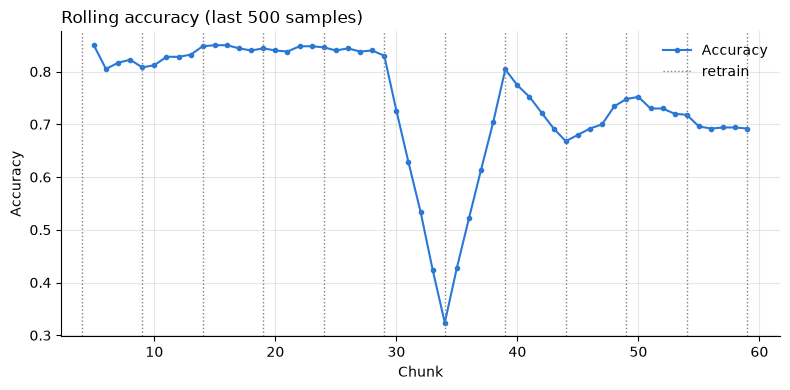

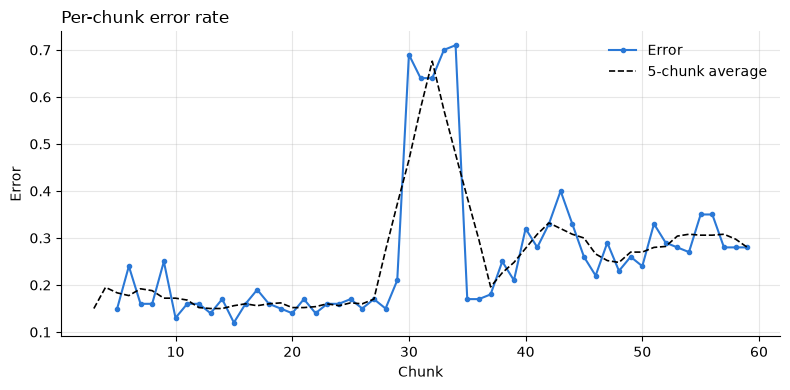

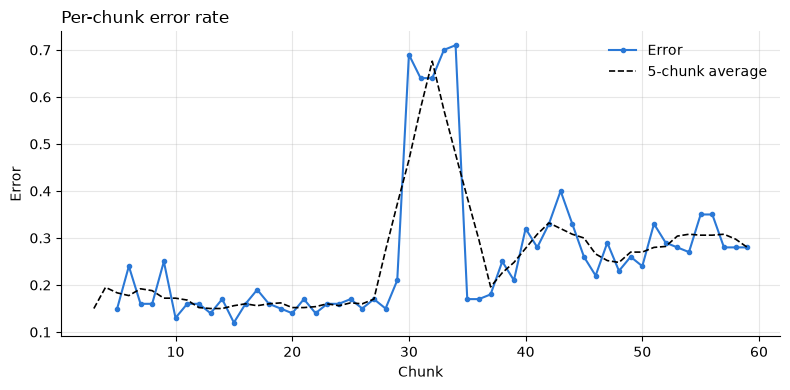

In [7]:
retrains = np.flatnonzero(h["retrained"])
vis.plot_metric_over_time(h["rolling_accuracy"], title="Rolling accuracy (last 500 samples)",
                          ylabel="Accuracy", retrain_points=retrains,
                          save_path=FIG("rolling_accuracy.png"))
vis.plot_metric_over_time(h["chunk_error"], title="Per-chunk error rate", ylabel="Error",
                          smooth=5, save_path=FIG("chunk_error.png"))

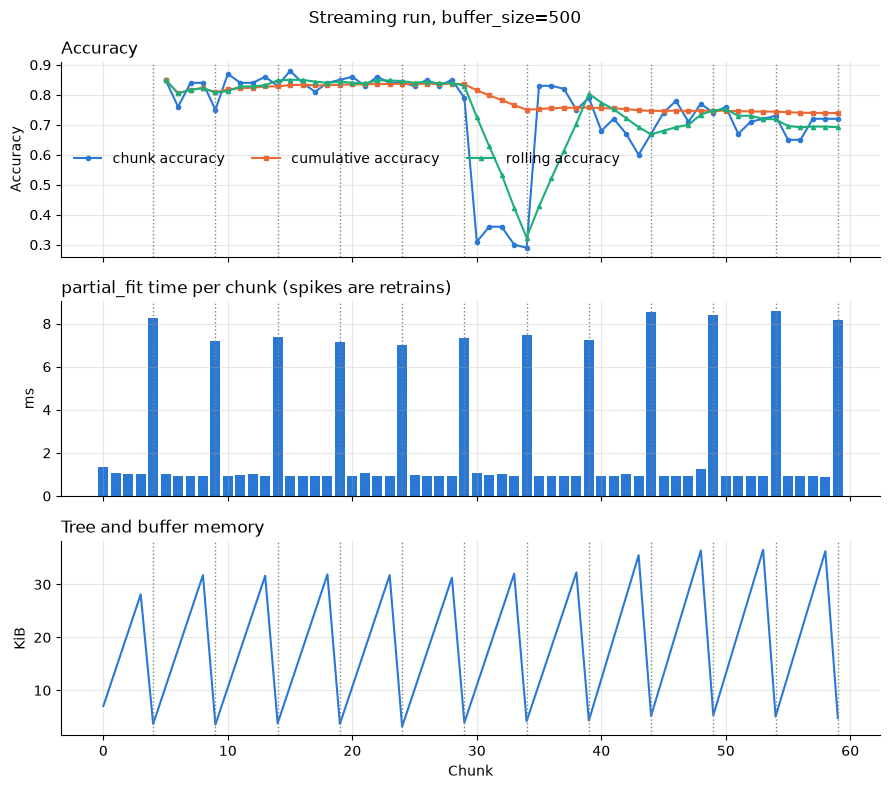

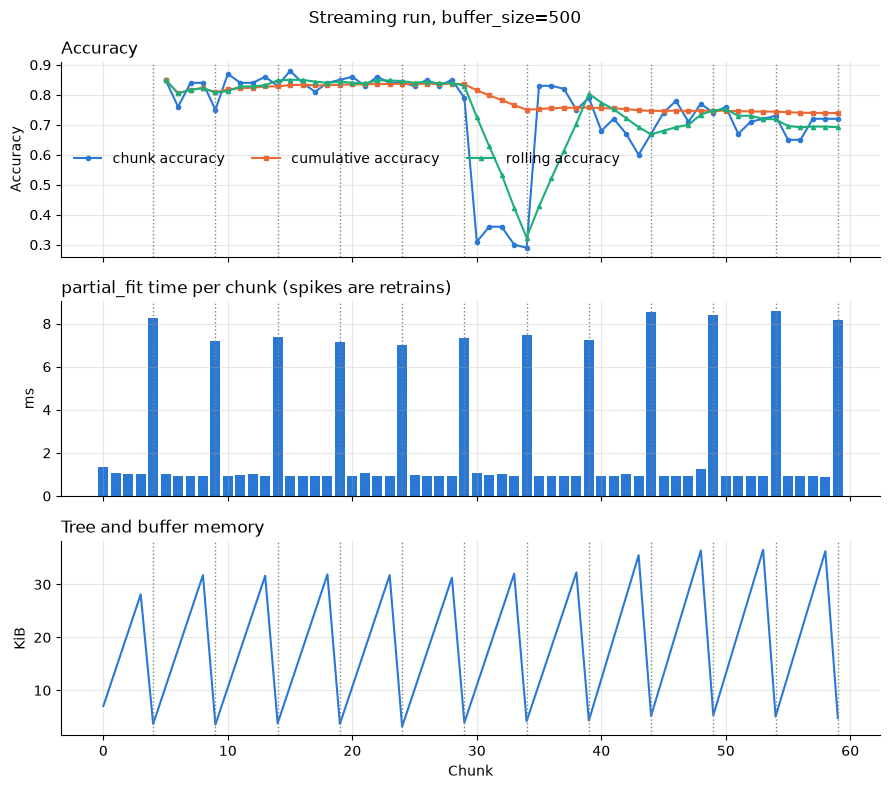

In [8]:
vis.plot_stream_dashboard(h, title="Streaming run, buffer_size=500",
                          save_path=FIG("dashboard.png"))

## 6. Comparing models: different `buffer_size` values, and gini vs entropy

A small buffer retrains often but each tree sees little data, so the trees are noisy. A
large buffer gives better trees but reacts slowly to the drift and starts predicting later.

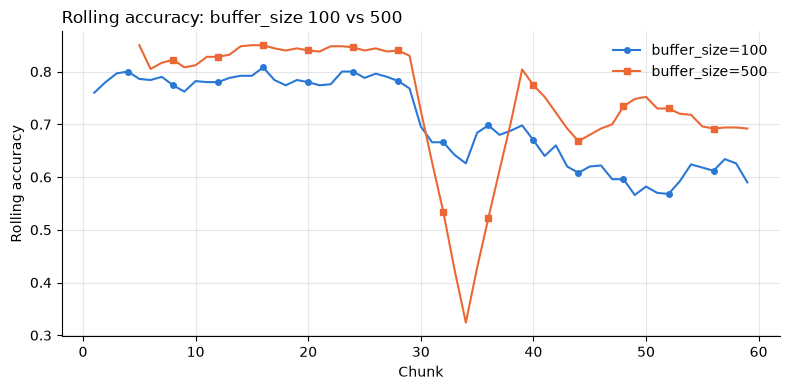

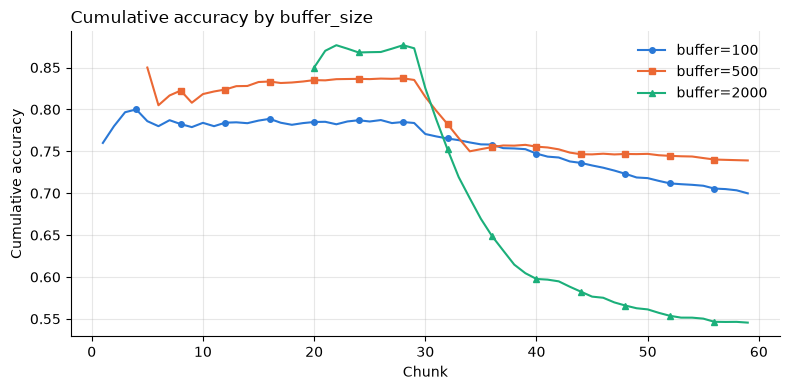

buffer=100           acc=0.700  f1=0.619  retrains= 60  fit time=0.159s
tree (buffer=500)    acc=0.739  f1=0.679  retrains= 12  fit time=0.139s
buffer=2000          acc=0.545  f1=0.435  retrains=  3  fit time=0.123s


In [9]:
def run_stream(model, name, **kwargs):
    tr = StreamTrainer(model, rolling_window=500, name=name, **kwargs)
    for c in nio.iter_csv_chunks(DATA, chunk_size=100, target="status", categorical=["site"]):
        tr.process_chunk(np.hstack([c.X.astype(object), c.X_cat]), c.y)
    return tr


small = run_stream(build_pipeline(100), "buffer=100")
large = run_stream(build_pipeline(2000), "buffer=2000")
vis.compare_models(small.history_arrays()["rolling_accuracy"], h["rolling_accuracy"],
                   labels=["buffer_size=100", "buffer_size=500"],
                   title="Rolling accuracy: buffer_size 100 vs 500", ylabel="Rolling accuracy",
                   save_path=FIG("compare_100_vs_500.png"))
vis.compare_models({"buffer=100": small.history_arrays()["cumulative_accuracy"],
                    "buffer=500": h["cumulative_accuracy"],
                    "buffer=2000": large.history_arrays()["cumulative_accuracy"]},
                   title="Cumulative accuracy by buffer_size", ylabel="Cumulative accuracy",
                   save_path=FIG("compare_buffers.png"))
for tr in (small, trainer, large):
    s = tr.summary()
    print(f"{s['name']:<20} acc={s['final_cumulative_accuracy']:.3f}  "
          f"f1={s['final_macro_f1']:.3f}  retrains={s['n_retrains']:>3}  "
          f"fit time={s['total_fit_seconds']:.3f}s")

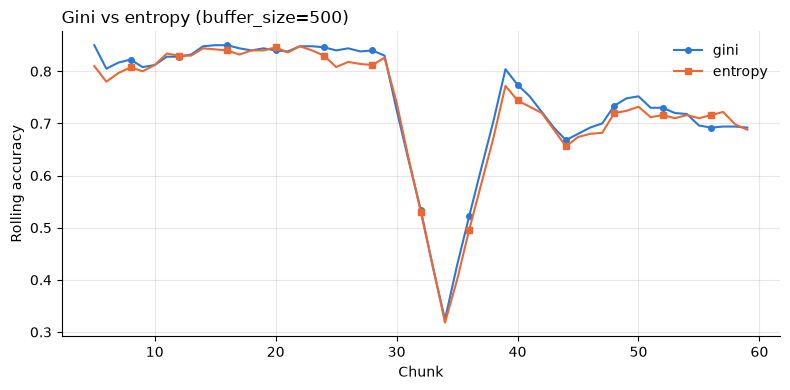

gini   : 0.7391
entropy: 0.7285


In [10]:
ent = run_stream(build_pipeline(500, criterion="entropy"), "entropy")
vis.compare_models(h["rolling_accuracy"], ent.history_arrays()["rolling_accuracy"],
                   labels=["gini", "entropy"], title="Gini vs entropy (buffer_size=500)",
                   ylabel="Rolling accuracy", save_path=FIG("gini_vs_entropy.png"))
print("gini   :", round(trainer.summary()["final_cumulative_accuracy"], 4))
print("entropy:", round(ent.summary()["final_cumulative_accuracy"], 4))

## 7. Extra: retraining when drift is detected

With a fixed `buffer_size` the tree only changes at the next scheduled retrain. I added a
`DDM` drift detector that watches the error rate. When it rises clearly, the trainer calls
`tree.flush(...)` and retrains straight away on the rows seen since the warning started.

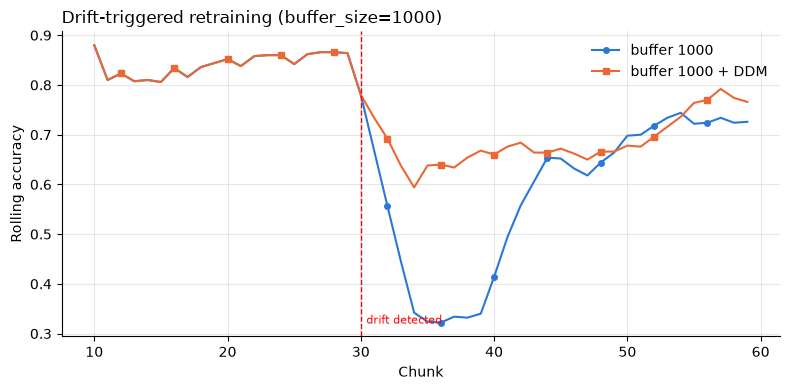

buffer 1000          acc=0.685  drift retrains=0  detected at chunk(s) []
buffer 1000 + DDM    acc=0.747  drift retrains=1  detected at chunk(s) [30]


In [11]:
plain = run_stream(build_pipeline(1000), "buffer 1000")
ddm = run_stream(build_pipeline(1000), "buffer 1000 + DDM", drift_detector=DDM(min_samples=200))
fig = vis.compare_models({t.name: t.history_arrays()["rolling_accuracy"] for t in (plain, ddm)},
                         title="Drift-triggered retraining (buffer_size=1000)",
                         ylabel="Rolling accuracy", show=False)
for c in np.flatnonzero(ddm.history_arrays()["drift"]):
    fig.axes[0].axvline(c, color="red", linestyle="--", linewidth=1)
    fig.axes[0].annotate("drift detected", (c, 0.32), xytext=(4, 0),
                         textcoords="offset points", fontsize=8, color="red")
fig.savefig(FIG("drift_detection.png"), dpi=150, bbox_inches="tight")
plt.show()
for t in (plain, ddm):
    s = t.summary()
    print(f"{t.name:<20} acc={s['final_cumulative_accuracy']:.3f}  "
          f"drift retrains={s['n_drift_retrains']}  "
          f"detected at chunk(s) {np.flatnonzero(t.history_arrays().get('drift', [])).tolist()}")

## 8. Predictions vs ground truth on the latest chunk, and the cumulative confusion matrix

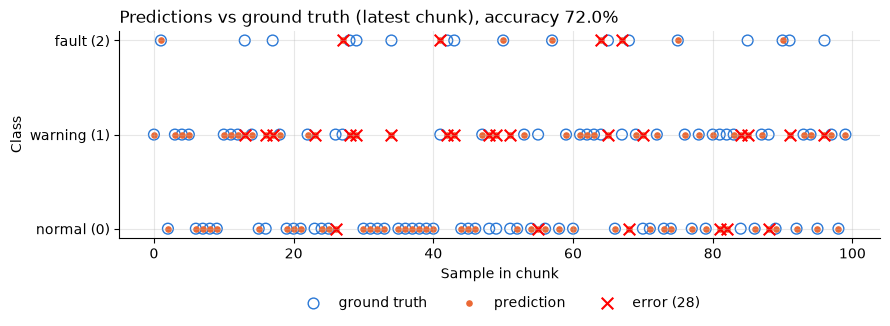

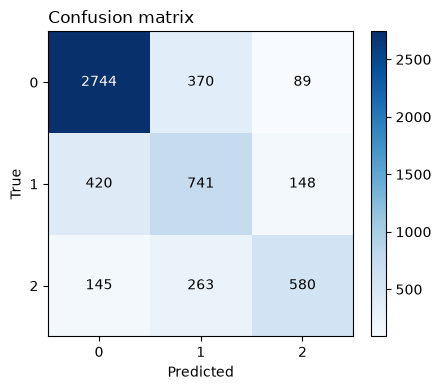

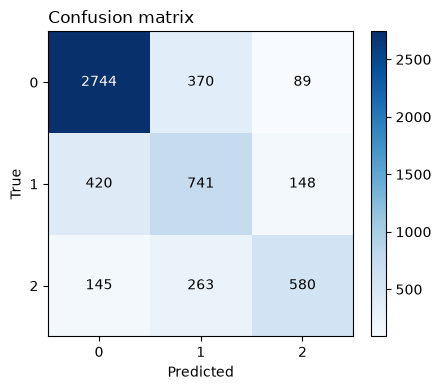

In [12]:
vis.plot_predictions_vs_ground_truth(trainer.last_truth, trainer.last_predictions,
                                     class_names=["normal (0)", "warning (1)", "fault (2)"],
                                     save_path=FIG("predictions_vs_truth.png"))
vis.plot_confusion_matrix(trainer.confusion.result(), labels=trainer.confusion.labels_,
                          save_path=FIG("confusion_matrix.png"))

## 9. Inspecting the latest tree

depth: 6 | leaves: 38 | features: ['temperature', 'vibration', 'pressure', 'humidity', 'load', 'site=B', 'site=C', 'site=A', 'site=D']


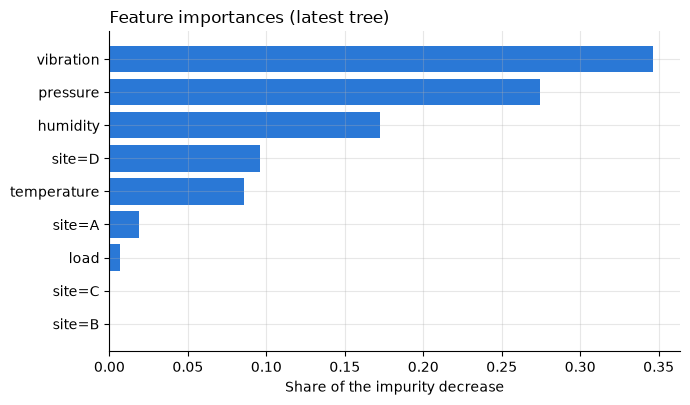

|--- vibration <= -0.131
|   |--- pressure <= 0.514
|   |   |--- humidity <= -0.219
|   |   |   |--- pressure <= -0.928
|   |   |   |   |--- class: 0 (n=23)
|   |   |   |--- pressure >  -0.928
|   |   |   |   |--- site=D <= 0.5
|   |   |   |   |   |--- vibration <= -0.897
|   |   |   |   |   |   |--- class: 1 (n=13)
|   |   |   |   |   |--- vibration >  -0.897
|   |   |   |   |   |   |--- class: 0 (n=34)
|   |   |   |   |--- site=D >  0.5
|   |   |   |   |   |--- temperature <= 0.414
|   |   |   |   |   |   |--- class: 1 (n=13)
|   |   |   |   |   |--- temperature >  0.414
|   |   |   |   |   |   |--- class: 1 (n=5)
|   |   |--- humidity >  -0.219
|   |   |   |--- pressure <= 0.104
|   |   |   |   |--- temperature <= -1.565
|   |   |   |   |   |--- class: 2 (n=6) 
...


In [13]:
tree = trainer.model["tree"]
names = trainer.model["pre"].get_feature_names_out(ds.numeric_names + ds.categorical_names)
print("depth:", tree.get_depth(), "| leaves:", tree.get_n_leaves(), "| features:", names)
vis.plot_feature_importances(tree.feature_importances_, names,
                             title="Feature importances (latest tree)",
                             save_path=FIG("feature_importances.png"))
print("\n".join(tree.export_text(names).splitlines()[:20]), "\n...")

## 10. Predicting new data

Between retrains `predict()` uses the latest tree. New readings, here one with a missing
value, go straight through the pipeline:

In [14]:
new = np.array([[75.0, 6.1, np.nan, 50.0, 0.9, "D"],
                [55.0, 1.2, 130.0, 70.0, 0.1, "A"]], dtype=object)
print("predicted status :", pipe.predict(new))
print("class probability:\n", pipe.predict_proba(new).round(3))
print("samples waiting in buffer:", tree.buffer_count)

predicted status : [0 2]
class probability:
 [[1. 0. 0.]
 [0. 0. 1.]]
samples waiting in buffer: 0


## Summary

* Every part (I/O, statistics, imputer, scaler, one-hot encoder, tree, metrics) worked
  chunk by chunk with `partial_fit` or `update`.
* The buffered tree recovers from the drift after a retrain. `buffer_size` trades how fast
  it reacts and how often it retrains against how good each tree is.
* DDM found the drift shortly after chunk 30 and retrained early (`benchmark/` has the
  numbers over 3 streams).
* Figures are in `demo/figures/` and the per-chunk log is in `demo/stream_log.csv`.